In [2]:
import numpy as np
import pandas as pd
import spacy

In [3]:
#Read your train and test set
train = pd.read_csv('train_tickets.csv')
test = pd.read_csv('test_tickets.csv')



In [4]:
train

,Unnamed: 0,content,class
0,76,"In RGB mode stuck, lightsaber has become Hmm.....",Software issue
1,124,"Broken pc Hey, last Thursday my pc fell to the...",Purchase requisition
2,5,Ergonomic Chair Purchase We're running low on ...,Purchase requisition
3,116,Privacy glass on the windows It would be reall...,Privacy issue
4,163,Request for updated design software license Th...,Software issue
...,...,...,...
130,104,To many places in the building with cameras I ...,Privacy issue
131,129,Model deployment pipeline fails at Docker buil...,Software issue
132,183,IT Training Request Requesting training sessio...,Purchase requisition
133,174,Keyboard Not Responding The printer driver nee...,Software issue


In [5]:
train.drop("Unnamed: 0",axis=1 ,inplace=True)
test.drop("Unnamed: 0",axis=1 ,inplace=True)

C:\Users\nolan\AppData\Local\Temp\ipykernel_75680\1600316279.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  train.drop("Unnamed: 0",axis=1 ,inplace=True)
C:\Users\nolan\AppData\Local\Temp\ipykernel_75680\1600316279.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  test.drop("Unnamed: 0",axis=1 ,inplace=True)


In [6]:
#Get the specific data as informed bellow
X_train = train['content']
y_train = train['class']

X_test = test['content']
y_test = test['class']

In [7]:
nlp = spacy.load('en_core_web_sm', disable = ['tagger','parser','ner'])

In [8]:
#Create a function to transform tickets in tokens

def tokenize_tickets(tickets):
    return [ticket.split() for ticket in tickets]

X_train_tokens = tokenize_tickets(X_train)
X_test_tokens = tokenize_tickets(X_test)

In [9]:
from tqdm import tqdm

clean_train_tickets = []
clean_train_tickets = tokenize_tickets(X_train)


#Apply the previous function to the X_train
 

In [10]:
clean_train_tickets

[['In',
  'RGB',
  'mode',
  'stuck,',
  'lightsaber',
  'has',
  'become',
  'Hmm...',
  'a',
  'problem,',
  'there',
  'is.',
  'After',
  'installing',
  'the',
  'latest',
  'security',
  'update,',
  'broken',
  'my',
  'lightsaber',
  'has',
  'become.',
  'No',
  'longer',
  'stable,',
  'its',
  'blade',
  'is.',
  'RGB',
  'mode,',
  'it',
  'now',
  'displays—red,',
  'blue,',
  'green—flashing',
  'endlessly,',
  'it',
  'is.',
  'Balance,',
  'there',
  'is',
  'not.',
  'A',
  'disco,',
  'it',
  'seems',
  'to',
  'have',
  'become.',
  'Use',
  'in',
  'battle,',
  'impossible',
  'it',
  'now',
  'is.',
  'A',
  "Jedi's",
  'tool,',
  'a',
  'toy',
  'it',
  'should',
  'not',
  'be.',
  'Fix',
  'it,',
  'you',
  'must.'],
 ['Broken',
  'pc',
  'Hey,',
  'last',
  'Thursday',
  'my',
  'pc',
  'fell',
  'to',
  'the',
  'floor',
  'and',
  'I',
  'wanted',
  'to',
  'know',
  'the',
  'procedure',
  'to',
  'require',
  'a',
  'new',
  'one.',
  'Sorry',
  'for',
  't

In [24]:
from sklearn.feature_extraction.text import CountVectorizer



#Create a CountVectorizer object 

vectorizer = CountVectorizer(token_pattern=r'(?u)\b[a-zA-Z]{2,}\b')
train_data_features = vectorizer.fit_transform(X_train)
















In [25]:
vocab = vectorizer.get_feature_names_out()
print(vocab)

['ability' 'able' 'about' ... 'yet' 'you' 'your']


In [26]:
train_data_features[0].toarray()

array([[0, 0, 0, ..., 0, 1, 0]], shape=(1, 1306))

In [27]:
from sklearn.naive_bayes import MultinomialNB
classifier = MultinomialNB()

classifier.fit(train_data_features, y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](3,)","[45.,37.,53.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](3,)","[-1.1 ,-1.29,-0.93]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[<U20](3,)","['Privacy issue','Purchase requisition','Software issue']"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](3, 1306)","[[ 0., 0., 9.,..., 0.,11., 6.], [ 1., 1., 1.,..., 1., 2., 0.], [ 1., 0., 3.,..., 0.,15., 1.]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](3, 1306)","[[-7.97,-7.97,-5.67,...,-7.97,-5.49,-6.03], [-7.14,-7.14,-7.14,...,-7.14,-6.73,-7.83], [-7.31,-8. ,-6.62,...,-8. ,-5.23,-7.31]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1306


Preprocess and transform the test set!

In [32]:
clean_test_reviews = []

#perform the data processing in our test set

clean_test_reviews = test['content']
test_data_features = vectorizer.transform(clean_test_reviews)




In [33]:
clean_test_reviews

0     Update issues In our most recent update many e...
1     Im working well im bored so im making a ticket...
2     Customer data sync error Customer changed thei...
3     Software Update Problems Requesting an update ...
4     Request for New Monitors We need to purchase 1...
5     Unable to Access Corporate VPN Dear IT Team,  ...
6     Lockt out Well, I'm locked out of my account d...
7     Privacy Policy Update Our privacy policy needs...
8     Slow database query Some standard database que...
9     External Hard Drive Purchase We need to buy ex...
10    Firewall Upgrade Our current firewall is outda...
11    Phone Request john here i need a new phone my ...
12    new hardware - 12 Jetank and Jetracers Hey , I...
13    Potential Unauthorized Access to Confidential ...
14    New Gantt chart software I believe that the so...
15    Data Breach Report We suspect a data breach in...
16    Suspected Data breach There has been unusual a...
17    Vendor Data Handling Assessment Assess how

In [34]:
test_data_features

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 1075 stored elements and shape (59, 1306)>

Check your score

In [35]:
#check the score
classifier.score(test_data_features, y_test)

0.8135593220338984

Look at your results and compare with your ground truth

In [36]:
#check the prediction
results = classifier.predict(test_data_features)
results

array(['Software issue', 'Software issue', 'Privacy issue',
       'Software issue', 'Purchase requisition', 'Software issue',
       'Privacy issue', 'Privacy issue', 'Software issue',
       'Purchase requisition', 'Purchase requisition', 'Software issue',
       'Purchase requisition', 'Privacy issue', 'Purchase requisition',
       'Privacy issue', 'Privacy issue', 'Privacy issue',
       'Software issue', 'Purchase requisition', 'Software issue',
       'Software issue', 'Software issue', 'Privacy issue',
       'Software issue', 'Software issue', 'Privacy issue',
       'Purchase requisition', 'Privacy issue', 'Purchase requisition',
       'Software issue', 'Privacy issue', 'Purchase requisition',
       'Software issue', 'Software issue', 'Software issue',
       'Software issue', 'Purchase requisition', 'Privacy issue',
       'Software issue', 'Purchase requisition', 'Purchase requisition',
       'Software issue', 'Software issue', 'Software issue',
       'Purchase requisit

In [37]:
y_test

0           Software issue
1            Privacy issue
2           Software issue
3           Software issue
4     Purchase requisition
5           Software issue
6           Software issue
7            Privacy issue
8           Software issue
9     Purchase requisition
10    Purchase requisition
11    Purchase requisition
12    Purchase requisition
13           Privacy issue
14    Purchase requisition
15           Privacy issue
16           Privacy issue
17           Privacy issue
18          Software issue
19    Purchase requisition
20          Software issue
21          Software issue
22          Software issue
23    Purchase requisition
24          Software issue
25          Software issue
26           Privacy issue
27    Purchase requisition
28           Privacy issue
29    Purchase requisition
30          Software issue
31    Purchase requisition
32    Purchase requisition
33          Software issue
34          Software issue
35          Software issue
36          Software issue
3

Plot a confusion matrix

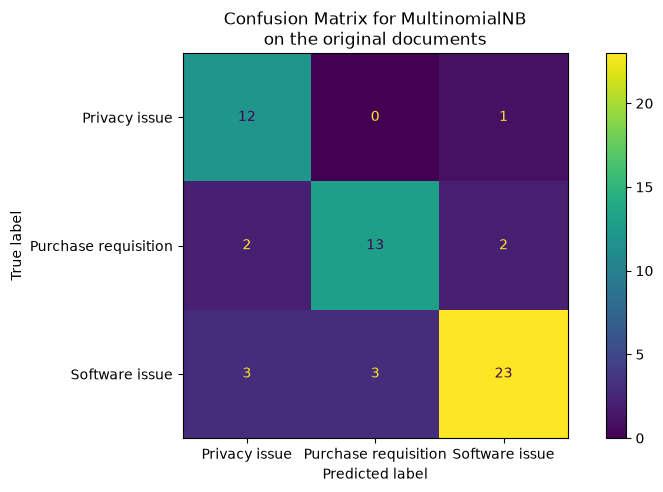

In [38]:
import matplotlib.pyplot as plt

from sklearn.metrics import ConfusionMatrixDisplay

target_names = ['Privacy issue', 'Purchase requisition', 'Software issue']

fig, ax = plt.subplots(figsize=(10, 5))
ConfusionMatrixDisplay.from_predictions(y_test, results, ax=ax)
ax.xaxis.set_ticklabels(target_names)
ax.yaxis.set_ticklabels(target_names)
_ = ax.set_title(f"Confusion Matrix for {classifier.__class__.__name__}\non the original documents")

**Not bad, right?**

Now is your time to play!


---> we use 5000 features, which can consist of unigrams (single words) or bigrams, when using the code below:

vectorizer = CountVectorizer(analyzer = 'word',
                             max_features = 5000,
                             ngram_range=(1,2))


What you should do:
- Try to check another parameters, another combination and train your naive bayes model

In [ ]:
vectorizer = CountVectorizer(analyzer='word', max_features=5000, ngram_range=(1,2),token_pattern=r'(?u)\b[a-zA-Z]{2,}\b')

train_data_features = vectorizer.fit_transform(train['content'])
test_data_features = vectorizer.transform(test['content'])

classifier = MultinomialNB()
classifier.fit(train_data_features, y_train)
print(classifier.score(test_data_features, y_test))

0.847457627118644


### Next

Apply other models:
- LogisticRegression
- BernoulliNB
- DecisionTreeClassifier



In [47]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import BernoulliNB
from sklearn.tree import DecisionTreeClassifier

models = {
    "MultinomialNB": MultinomialNB(),
    "LogisticRegression": LogisticRegression(max_iter=1000),
    "BernoulliNB": BernoulliNB(),
    "DecisionTree": DecisionTreeClassifier(random_state=42),
}

for name, model in models.items():
    model.fit(train_data_features, y_train)
    print(name, model.score(test_data_features, y_test))

MultinomialNB 0.847457627118644
LogisticRegression 0.7966101694915254
BernoulliNB 0.5423728813559322
DecisionTree 0.6440677966101694


**Question:** Would you try a Neural Network in this data? Explain your thoughts.

In [ ]:
i would not use a nn because we have little data and the accuracy is already ok.

